# Linear map for the Riccati equations

`Riccati_Linear.Dynamics_Linear` replaces the nested ODEs $\sigma \to \bar r \to s$ of the General case by one matrix exponential per branch pair (Sec. `subsec:riccati`, App. `app:doubling`, extended to $\bar r$ and $s$; the identities are in the module docstring). It covers unitary and open dynamics through `solver='linear'`.

The solvers compared here are the **linear map**, the library's **nested ODEs**, and **QuTiP** (`mesolve` in a truncated Fock space, built from the master equation only, `tests/qutip_reference.py`). The numerical reference in (a) and (d) is `Joint_ODE`: $(\sigma, \bar r, s)$ integrated together at `rtol=1e-13`, with no interpolation, so it shares no code with the linear map.

In [1]:
import os, platform, sys, time

# One BLAS thread for every timing below: the default threading adds noise to small matrix operations
for variable in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS'):
    os.environ[variable] = '1'

import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath('../src'))
sys.path.append(os.path.abspath('../tests'))

import Gaussian
import qutip
import qutip_reference as Q
from Riccati_Linear import Dynamics_Linear
from test_riccati_linear import (Problem, ODE_Solver, Joint_ODE, Rotation, Example_1, Example_1_Off_Diagonal, Example_1_Exponent_Rates,
                                 EXAMPLE_1, ROTATIONS, QuTiP_Problem, Mixed_Qubits, Open_Noise, Weighted_Errors)

LINEAR, ODE, QUTIP = dict(color='#2a78d6', marker='o', label='linear'), dict(color='#eb6834', marker='s', label='nested ODE'), dict(color='#1baf7a', marker='^', label='QuTiP')
JOINT = dict(color='#eda100', marker='D', label='joint ODE')
plt.rcParams.update({'figure.dpi': 80, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e5e0', 'lines.linewidth': 2, 'lines.markersize': 7})

def Table(header, rows):
    widths = [max(len(str(x)) for x in column) for column in zip(header, *rows)]
    for row in [header] + rows:
        print('  '.join(str(x).rjust(w) for x, w in zip(row, widths)))

def Sci(x):
    return f'{x:.1e}'

print(platform.platform(), platform.processor(), f'{os.cpu_count()} cores | numpy', np.__version__, '| qutip', qutip.__version__)

macOS-26.6.2-arm64-arm-64bit arm 8 cores | numpy 1.26.4 | qutip 5.3.1


## (a) Linear map against the nested ODEs

Two qubits, one mode, every term of Tab. 3 on in the open case. Errors are max-norm against `Joint_ODE` over all branches and times.

   case  grid  ode sigma    ode r    ode C  ode phi  lin sigma    lin r    lin C  lin phi
unitary    21    1.5e-10  7.7e-05  8.0e-05  9.8e-05    2.9e-13  4.6e-14  2.0e-14  2.1e-14
unitary   101    2.0e-10  1.6e-07  1.4e-07  1.4e-07    3.3e-13  6.3e-14  3.4e-14  2.9e-14
unitary   401    2.5e-10  7.8e-10  1.0e-09  7.0e-10    3.4e-13  1.1e-13  9.3e-14  5.0e-14
unitary  1601    2.5e-10  5.4e-10  2.7e-10  1.3e-10    4.3e-13  1.9e-13  3.0e-13  1.6e-13
   open    21    5.8e-10  1.3e-04  6.8e-05  1.0e-04    8.6e-13  7.7e-14  3.4e-14  3.6e-14
   open   101    8.7e-10  1.5e-07  2.2e-07  2.1e-07    8.5e-13  9.9e-14  5.6e-14  4.2e-14
   open   401    8.8e-10  3.6e-09  1.7e-09  3.5e-09    1.7e-12  1.3e-13  6.7e-14  5.5e-14
   open  1601    9.3e-10  7.8e-10  2.6e-10  2.8e-10    2.1e-12  2.6e-13  3.1e-13  1.6e-13


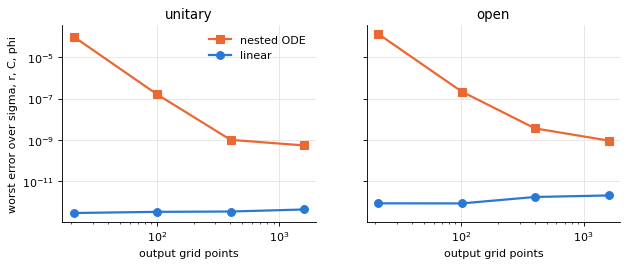

In [2]:
problem, noise = Problem(2, 1, open_system=True)
grids = [21, 101, 401, 1601]
rows, results = [], {'unitary': [], 'open': []}
for name, kwargs in (('unitary', {}), ('open', noise)):
    for points in grids:
        t = np.linspace(0, 6, points)
        reference = Joint_ODE(2, 1, problem, kwargs, t)
        ode = [np.max(np.abs(a - b)) for a, b in zip(ODE_Solver(2, 1, problem, kwargs, t), reference)]
        linear = [np.max(np.abs(a - b)) for a, b in zip(Dynamics_Linear(2, 1, *problem, t, **kwargs), reference)]
        results[name].append((max(ode), max(linear)))
        rows.append([name, points] + [Sci(x) for x in ode + linear])
Table(['case', 'grid', 'ode sigma', 'ode r', 'ode C', 'ode phi', 'lin sigma', 'lin r', 'lin C', 'lin phi'], rows)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (name, values) in zip(axes, results.items()):
    ax.loglog(grids, [v[0] for v in values], **ODE)
    ax.loglog(grids, [v[1] for v in values], **LINEAR)
    ax.set_title(name)
    ax.set_xlabel('output grid points')
axes[0].set_ylabel('worst error over sigma, r, C, phi')
axes[0].legend(frameon=False)
plt.show()

The large nested-ODE error on coarse grids is an artefact of how the library couples its three ODEs, not a limit of ODE integration. The nested solvers pass $\sigma$ and $\bar r$ on through `interp1d(kind='cubic')` built on `t_eval`, not on the solver's own steps, so their accuracy depends on the output grid and tightening `rtol` does not help. Integrating the three together removes it: see the joint ODE in (d). The linear map is exact at each grid time for any grid, up to round-off.

## (b) Linear map against the paper's analytical solutions

Conditional rotations (App. l. 1653) and the dispersive plus parametric-amplifier example (App. l. 1811). `tests/test_riccati_linear.py` holds the formulas.

In [3]:
rows = []
for theta_bar, theta_delta, s in ROTATIONS:
    x_0, p_0 = 0.8, -0.5
    sigma, r, C, phi = Rotation(theta_bar, theta_delta, s, x_0, p_0)
    c, t_ = np.cos(theta_delta), np.sin(theta_delta)
    cb, sb = np.cos(theta_bar), np.sin(theta_bar)
    z_1, z_2 = s*c + 1j*t_, c + 1j*s*t_
    sigma_paper = np.array([[cb**2*z_2/z_1 + sb**2*z_1/z_2, (s**2 - 1)*sb*cb/(z_1*z_2)], [(s**2 - 1)*sb*cb/(z_1*z_2), cb**2*z_1/z_2 + sb**2*z_2/z_1]])
    r_paper = np.array([[cb, sb], [-sb, cb]]) @ np.array([s*x_0/z_1, p_0/z_2])
    rho_paper = np.sqrt(s)*np.exp(-1j*t_*(p_0**2/z_2 + s*x_0**2/z_1))/(np.sqrt(z_1)*np.sqrt(z_2))
    rows.append([theta_bar, theta_delta, s, Sci(np.max(np.abs(sigma[-1, 1, 0] - sigma_paper))), Sci(np.max(np.abs(r[-1, 1, 0, :, 0] - r_paper))),
                 Sci(abs(np.exp(-C[-1, 1, 0] + 1j*phi[-1, 1, 0]) - rho_paper))])
print('Conditional rotations at tau = 1')
Table(['theta_bar', 'theta_delta', 's', 'sigma off', 'r off', 'rho off'], rows)

tau = np.linspace(0, 40, 2001)
sigma, r, C, phi = Example_1(tau)
closed = [Example_1_Off_Diagonal(x, *EXAMPLE_1) for x in tau[1:]]
s_rate = np.gradient(-C[:, 1, 0] + 1j*phi[:, 1, 0], tau, edge_order=2)[1:-1]
r_part, sigma_part = Example_1_Exponent_Rates(tau[1:-1], *EXAMPLE_1)
print('\nExample 1, kappa, lambda, mu, alpha, phi =', EXAMPLE_1, 'on tau in [0, 40]')
print('sigma off', Sci(max(np.max(np.abs(np.diag(sigma[i + 1, 1, 0]) - c[0])) for i, c in enumerate(closed))))
print('r off    ', Sci(max(np.max(np.abs(r[i + 1, 1, 0, :, 0] - c[1])) for i, c in enumerate(closed))))
print('ds/dt    ', Sci(np.max(np.abs(s_rate - r_part - sigma_part))), '(finite difference of the solver output, h = 0.02)')

Conditional rotations at tau = 1
theta_bar  theta_delta    s  sigma off    r off  rho off
      0.7          0.4  1.8    2.2e-14  3.9e-14  3.1e-14
      0.3          1.2  0.4    4.5e-14  1.0e-13  7.8e-14
      2.2          2.6  2.5    1.2e-14  5.3e-14  4.6e-14
     -0.4          4.4  3.0    2.5e-14  1.4e-13  7.6e-14

Example 1, kappa, lambda, mu, alpha, phi = (0.6, 0.2, 0.5, 0.7, 0.4) on tau in [0, 40]
sigma off 5.2e-15
r off     8.7e-15
ds/dt     4.3e-05 (finite difference of the solver output, h = 0.02)


**Where the paper needed correcting.** Each item has a test in `tests/test_riccati_linear.py` that keeps the corrected form and records that the typed form fails; QuTiP is the referee where marked.

| Where | As typed | Correct | Evidence |
|---|---|---|---|
| Tab. 1, $\dot\sigma$ | $+i\Omega\Delta\Omega$ | $-i\Omega\Delta\Omega$ (as Tab. 3) | QuTiP: error 0.52 vs 3e-10 |
| Tab. 1, $\dot{\bar r}$ | $-i\sigma(r_j-r_k)$ | $+i\sigma(r_j-r_k)$ (as Tab. 3) | QuTiP: error 0.89 vs 1e-10 |
| App. l. 1584 | $D$ inside the $\tfrac12$ | $D$ outside | ODE: error 2.1 vs 6e-13 |
| Eq. `lindo` | $\{\varrho, \hat r^a\hat r^b\}$ | $\{\varrho, \hat r^b\hat r^a\}$ | typed form is not trace preserving |
| App. l. 1692 | one principal $\log$ of the product | logs kept separate and continuous | sign of $\exp(s)$ wrong for $\theta_\Delta\in(\pi/2,3\pi/2)$ mod $2\pi$; l. 1696 is right |
| Eq. l. 1026 vs l. 1034 | $\tfrac{\mu}{2}(a^\dagger a+\tfrac12)\hat\sigma_z$ vs $H_j=\lambda\sigma_x+j\mu\mathbb 1$ | factor of 2 between them | QuTiP on l. 1026 agrees with $H_q=\mu/2$ |
| App. l. 1822 | $\omega_{\mu,\lambda}=\sqrt{\mu^2-\lambda^2}$ | $\sqrt{\lambda^2-\mu^2}$ | direct exponential |
| App. l. 1829 | $\bar r^{\rm on}_\pm(\infty)$ | overall sign flipped | QuTiP |
| App. l. 1919 | steady-state equations | $A\sigma+\sigma A^{\rm T}+\kappa\mathbb 1-i\mu(\sigma^2-\mathbb 1)=0$, $A=\lambda\Omega\sigma_x-\tfrac{\kappa}{2}\mathbb 1$ | residual 0.98 vs 2e-10 |
| Eqs. `rate_sigma`, `rate_r` | $\Gamma=\text{Im}[\dots]$ | opposite sign for $\sigma^{\rm off}=\sigma_{+1,-1}$ | $\dot{\mathcal C}$ of the solver |
| App. l. 1904 | first limit labelled $\dot{\mathcal C}_{\bar r}$ | is $\dot{\mathcal C}_\sigma$ | both limits hold to 1e-10 |

## (c) Linear map against QuTiP

One qubit in a mixed state and one displaced squeezed thermal mode, with loss, gain and measurement-type noise (so $E\neq0$), drive and dephasing. $\bar r_{jk}$ and $\sigma_{jk}$ are divided by Tr$[\varrho_{jk}]$, so they are compared weighted by $|\varrho_{jk}|$, which is what the Fock calculation resolves. `edge` is the population on the last Fock level.

   case  cutoff     edge    rho_q  r (weighted)  sigma (weighted)
unitary      20  6.3e-14  1.1e-10       7.3e-11           7.6e-10
unitary      30  2.5e-21  1.6e-10       1.1e-10           1.1e-09
unitary      45  2.3e-32  2.7e-10       2.8e-10           2.2e-09
   open      20  4.6e-07  2.4e-09       2.9e-06           2.5e-05
   open      30  2.3e-10  1.7e-10       1.9e-09           2.6e-08
   open      45  3.1e-15  2.6e-10       5.2e-10           2.7e-09


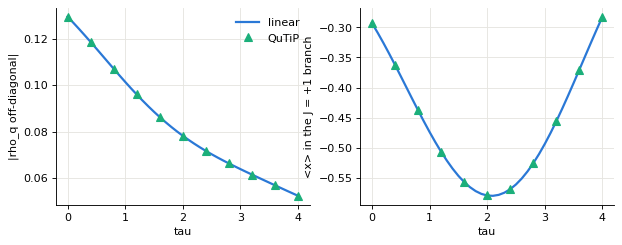

Larger systems, unitary (edge is the guard, cutoff in the last column)
qubits  modes     edge    rho_q  r (weighted)  sigma (weighted)  cutoff
     2      1  4.6e-16  5.8e-11       4.3e-10           1.1e-09      30
     1      2  3.3e-08  2.8e-09       1.9e-07           1.4e-06      20


In [4]:
mode_states, r_0, sigma_0, H_array, r_array, H_q_0 = QuTiP_Problem(1, 1)
rho_q_0 = Mixed_Qubits(1)
B, d = Open_Noise(1)
E, D = Gaussian.Get_Decoherence_Rates(1, B)
Gamma_z = np.array([0.2])
t = np.linspace(0, 4, 41)
setups = {'unitary': ({}, {}), 'open': (dict(B=B, d=d, Gamma_z=Gamma_z), dict(E=E, D=D, d=d, Gamma_z=Gamma_z))}

rows, runs = [], {}
for name, (noise_q, noise_l) in setups.items():
    linear = Dynamics_Linear(1, 1, r_0, sigma_0, H_array, r_array, H_q_0, rho_q_0, t, **noise_l)
    for cutoff in (20, 30, 45):
        reference = Q.Reference_Dynamics(1, 1, cutoff, mode_states, H_array, r_array, H_q_0, rho_q_0, t, **noise_q)
        rows.append([name, cutoff, Sci(reference[3])] + [Sci(x) for x in Weighted_Errors(reference, linear, rho_q_0)])
    runs[name] = linear, reference
Table(['case', 'cutoff', 'edge', 'rho_q', 'r (weighted)', 'sigma (weighted)'], rows)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
linear, reference = runs['open']
sparse = LINEAR | dict(marker=None)
axes[0].plot(t, np.abs(np.exp(-linear[2][:, 1, 0] + 1j*linear[3][:, 1, 0])*rho_q_0[1, 0]), **sparse)
axes[0].plot(t[::4], np.abs(reference[0][::4, 1, 0]), ls='none', **QUTIP)
axes[0].set_ylabel('|rho_q off-diagonal|')
axes[1].plot(t, linear[1][:, 1, 1, 0, 0].real, **sparse)
axes[1].plot(t[::4], reference[1][::4, 1, 1, 0, 0].real, ls='none', **QUTIP)
axes[1].set_ylabel('<x> in the J = +1 branch')
for ax in axes:
    ax.set_xlabel('tau')
axes[0].legend(frameon=False)
plt.show()

print('Larger systems, unitary (edge is the guard, cutoff in the last column)')
rows = []
for N_qubits, n_modes, cutoff in ((2, 1, 30), (1, 2, 20)):
    mode_states_2, r_2, sigma_2, H_2, f_2, H_0_2 = QuTiP_Problem(N_qubits, n_modes)
    rho_2 = Mixed_Qubits(N_qubits)
    t_2 = np.linspace(0, 1.5, 7)
    reference = Q.Reference_Dynamics(N_qubits, n_modes, cutoff, mode_states_2, H_2, f_2, H_0_2, rho_2, t_2)
    linear_2 = Dynamics_Linear(N_qubits, n_modes, r_2, sigma_2, H_2, f_2, H_0_2, rho_2, t_2)
    rows.append([N_qubits, n_modes, Sci(reference[3])] + [Sci(x) for x in Weighted_Errors(reference, linear_2, rho_2)] + [cutoff])
Table(['qubits', 'modes', 'edge', 'rho_q', 'r (weighted)', 'sigma (weighted)', 'cutoff'], rows)

## (d) Efficiency

BLAS runs on one thread throughout (set in the first cell). Wall time is the median of repeated `time.perf_counter` runs (up to 9 for the linear map and 5 otherwise, stopping early once a solver has used 10 s, so the slowest entries are single runs). **QuTiP times cover `mesolve` plus extracting the QRDM only**, which favours QuTiP: the other solvers also return every $\sigma_{jk}$ and $\bar r_{jk}$. QuTiP uses `rtol=1e-8`, `atol=1e-10`; a pure initial state makes `mesolve` evolve a ket, otherwise it evolves the density matrix. The ODE solver uses the library defaults (`rtol=1e-10`) unless stated.

**Fock cutoff.** Each QuTiP run takes the smallest cutoff on the ladder 10, 14, 20, 28, 40, 56, 80, 112, 160, 224, 320, 450, 640 whose QRDM changes by less than `dQ = 1e-6` at the next rung. The tables give the cutoff, `dQ`, and the disagreement `|Q-L|` with the linear map. A star on the cutoff means the ladder ran out before that test passed, so that QuTiP entry is not converged.

In [5]:
LADDER = [10, 14, 20, 28, 40, 56, 80, 112, 160, 224, 320, 450, 640]

def Median_Time(run, repeats=5, budget=10.0):
    times = []
    while len(times) < repeats and sum(times) < budget:
        start = time.perf_counter()
        result = run()
        times.append(time.perf_counter() - start)
    return float(np.median(times)), result

def Benchmark_Problem(N_qubits, n_modes, alpha=1.0, s=1.0):
    dim = 2*n_modes
    H_m = np.eye(dim)
    for m in range(n_modes - 1):
        for shift in (0, 1):
            H_m[2*m + shift, 2*m + 2 + shift] = H_m[2*m + 2 + shift, 2*m + shift] = 0.1
    H_array = [H_m] + [0.1*(i + 1)/N_qubits*np.eye(dim) + 0.05*np.diag(np.tile([1.0, -1.0], n_modes)) for i in range(N_qubits)]
    r_array = [np.zeros((dim, 1))] + [0.05*np.ones((dim, 1)) for _ in range(N_qubits)]
    mode_states = [(0.0, s, np.sqrt(2)*alpha, 0.0)]*n_modes
    sigma_0 = np.diag(np.tile([s, 1/s], n_modes)).astype(complex)
    r_0 = np.zeros((dim, 1), dtype=complex)
    r_0[::2] = np.sqrt(2)*alpha
    plus = np.ones(2**N_qubits, dtype=complex)/2**(N_qubits/2)
    return mode_states, (r_0, sigma_0, H_array, r_array, 0.2*np.ones(N_qubits), np.outer(plus, plus.conj()))

def Benchmark_Noise(N_qubits, n_modes):
    B = np.kron(np.eye(n_modes), 0.1*np.array([[1, -1j], [1j, 1]]) + 0.01*np.eye(2))
    E, D = Gaussian.Get_Decoherence_Rates(n_modes, B)
    d, Gamma_z = 0.1*np.ones((2*n_modes, 1)), 0.05*np.ones(N_qubits)
    return dict(B=B, d=d, Gamma_z=Gamma_z), dict(E=E, D=D, d=d, Gamma_z=Gamma_z)

def Rho(result, rho_q_0):
    return np.exp(-result[2] + 1j*result[3])*rho_q_0

def Time_QuTiP(N_qubits, n_modes, mode_states, problem, t, noise_q, cutoff, rtol=1e-8):
    _, _, H_array, r_array, H_q_0, rho_q_0 = problem
    return Median_Time(lambda: Q.Reference_Dynamics(N_qubits, n_modes, cutoff, mode_states, H_array, r_array, H_q_0, rho_q_0, t,
                                                    rtol=rtol, atol=rtol*1e-2, moments=False, **noise_q), repeats=3)

def Converged_QuTiP(N_qubits, n_modes, mode_states, problem, t, noise_q, start=0, tolerance=1e-6):
    previous, change = None, np.inf
    for cutoff in LADDER[start:]:
        cost, result = Time_QuTiP(N_qubits, n_modes, mode_states, problem, t, noise_q, cutoff)
        if previous is not None:
            change = np.max(np.abs(result[0] - previous[2][0]))
            if change < tolerance:
                return previous[0], previous[1], previous[2][0], change
        previous = cutoff, cost, result
    return f'{cutoff}*', cost, result[0], change

def Compare(N_qubits, n_modes, alpha=1.0, s=1.0, T=10.0, open_system=False, ode=True, qutip_run=True, start=0):
    mode_states, problem = Benchmark_Problem(N_qubits, n_modes, alpha, s)
    noise_q, noise_l = Benchmark_Noise(N_qubits, n_modes) if open_system else ({}, {})
    t = np.linspace(0, T, int(2*T) + 1)
    linear_time, linear = Median_Time(lambda: Dynamics_Linear(N_qubits, n_modes, *problem, t, **noise_l), repeats=9)
    rho_linear = Rho(linear, problem[-1])
    row = [Sci(linear_time)]
    if ode:
        ode_time, ode_result = Median_Time(lambda: ODE_Solver(N_qubits, n_modes, problem, noise_l, t), repeats=3)
        row += [Sci(ode_time), Sci(np.max(np.abs(Rho(ode_result, problem[-1]) - rho_linear)))]
    else:
        ode_time = np.nan
        row += ['-', '-']
    if qutip_run:
        cutoff, qutip_time, rho_qutip, change = Converged_QuTiP(N_qubits, n_modes, mode_states, problem, t, noise_q, start)
        row += [Sci(qutip_time), cutoff, Sci(change), Sci(np.max(np.abs(rho_qutip - rho_linear)))]
    else:
        qutip_time = np.nan
        row += ['-', '-', '-', '-']
    return row, (linear_time, ode_time, qutip_time)

HEADER = ['linear s', 'ODE s', '|ODE-L|', 'QuTiP s', 'cutoff', 'dQ', '|Q-L|']

### Time against achieved accuracy

One qubit, one mode, $\alpha=1.5$, $\tau\le10$. Error on the QRDM against `Joint_ODE` at `rtol=1e-13`, at 21 common times. The nested-ODE points differ in output grid size, the QuTiP points in cutoff and `rtol`. The **joint ODE** row is the fair ODE comparison: the same equations integrated together at `rtol=1e-10`, with no interpolation.

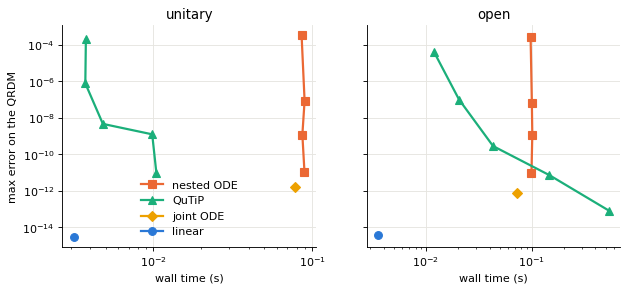

   case      solver                setting  time (s)    error
unitary   joint ODE  21 points, rtol 1e-10   7.8e-02  1.6e-12
unitary      linear              21 points   3.2e-03  2.9e-15
unitary  nested ODE              21 points   8.6e-02  3.3e-04
unitary      linear             101 points   8.3e-03  7.8e-15
unitary  nested ODE             101 points   9.0e-02  8.4e-08
unitary      linear             401 points   3.2e-02  5.4e-14
unitary  nested ODE             401 points   8.7e-02  1.2e-09
unitary      linear            1601 points   1.3e-01  5.7e-14
unitary  nested ODE            1601 points   9.0e-02  1.0e-11
unitary       QuTiP  cutoff 12, rtol 1e-06   3.7e-03  2.0e-04
unitary       QuTiP  cutoff 16, rtol 1e-06   3.7e-03  7.6e-07
unitary       QuTiP  cutoff 20, rtol 1e-08   4.8e-03  4.6e-09
unitary       QuTiP  cutoff 28, rtol 1e-10   9.8e-03  1.2e-09
unitary       QuTiP  cutoff 40, rtol 1e-12   1.0e-02  9.1e-12
   open   joint ODE  21 points, rtol 1e-10   7.3e-02  7.9e-13
   open 

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
rows = []
for ax, open_system in zip(axes, (False, True)):
    name = 'open' if open_system else 'unitary'
    mode_states, problem = Benchmark_Problem(1, 1, alpha=1.5)
    noise_q, noise_l = Benchmark_Noise(1, 1) if open_system else ({}, {})
    rho_q_0 = problem[-1]
    t = np.linspace(0, 10, 21)
    reference = Rho(Joint_ODE(1, 1, problem, noise_l, t), rho_q_0)

    points = {'linear': [], 'ODE': [], 'QuTiP': [], 'joint': []}

    cost, result = Median_Time(lambda: Joint_ODE(1, 1, problem, noise_l, t, rtol=1e-10, atol=1e-12))
    points['joint'].append((cost, np.max(np.abs(Rho(result, rho_q_0) - reference))))
    rows.append([name, 'joint ODE', '21 points, rtol 1e-10', Sci(points['joint'][0][0]), Sci(points['joint'][0][1])])

    for size in (21, 101, 401, 1601):
        t_grid = np.linspace(0, 10, size)
        cost_l, result_l = Median_Time(lambda: Dynamics_Linear(1, 1, *problem, t_grid, **noise_l), repeats=9)
        error_l = np.max(np.abs(Rho(result_l, rho_q_0)[::(size - 1)//20] - reference))
        if size == 21:
            points['linear'].append((cost_l, error_l))
        rows.append([name, 'linear', f'{size} points', Sci(cost_l), Sci(error_l)])
        cost, result = Median_Time(lambda: ODE_Solver(1, 1, problem, noise_l, t_grid))
        error = np.max(np.abs(Rho(result, rho_q_0)[::(size - 1)//20] - reference))
        points['ODE'].append((cost, error))
        rows.append([name, 'nested ODE', f'{size} points', Sci(cost), Sci(error)])

    for cutoff, tolerance in ((12, 1e-6), (16, 1e-6), (20, 1e-8), (28, 1e-10), (40, 1e-12)):
        cost, result = Time_QuTiP(1, 1, mode_states, problem, t, noise_q, cutoff, rtol=tolerance)
        error = np.max(np.abs(result[0] - reference))
        points['QuTiP'].append((cost, error))
        rows.append([name, 'QuTiP', f'cutoff {cutoff}, rtol {tolerance:.0e}', Sci(cost), Sci(error)])

    for key, style in (('ODE', ODE), ('QuTiP', QUTIP), ('joint', JOINT), ('linear', LINEAR)):
        ax.loglog(*zip(*points[key]), **style)
    ax.set_title(name)
    ax.set_xlabel('wall time (s)')
axes[0].set_ylabel('max error on the QRDM')
axes[0].legend(frameon=False)
plt.show()
Table(['case', 'solver', 'setting', 'time (s)', 'error'], rows)

### Time against system size

Unless a table says otherwise: output every $\Delta\tau=0.5$ up to $\tau=10$, and a pure qubit state $|+\rangle^{\otimes N}$. `-` means not run: the ODE at larger sizes is omitted for time, and open QuTiP with three modes needs a Liouvillian on $(2\cdot 14^3)^2\approx 3\times10^7$ elements.

In [7]:
curves = {}
def Sweep(title, values, make, label):
    rows, times = [], []
    for value in values:
        row, cost = make(value)
        rows.append([value] + row)
        times.append(cost)
    print(title)
    Table([label] + HEADER, rows)
    print()
    curves[title] = (values, times)

Sweep('Qubits, 1 mode, alpha 1.5, unitary', [1, 2, 3, 4], lambda N: Compare(N, 1, alpha=1.5), 'qubits')
Sweep('Qubits, 1 mode, alpha 1.5, open', [1, 2, 3], lambda N: Compare(N, 1, alpha=1.5, open_system=True), 'qubits')
Sweep('Modes, 1 qubit, alpha 0.7, unitary', [1, 2, 3, 4, 8], lambda n: Compare(1, n, alpha=0.7, ode=n <= 4, qutip_run=n <= 3), 'modes')
Sweep('Modes, 1 qubit, alpha 0.7, open', [1, 2, 3], lambda n: Compare(1, n, alpha=0.7, open_system=True, qutip_run=n <= 2), 'modes')

Qubits, 1 mode, alpha 1.5, unitary
qubits  linear s    ODE s  |ODE-L|  QuTiP s  cutoff       dQ    |Q-L|
     1   3.0e-03  8.4e-02  3.3e-04  4.3e-03      20  1.3e-09  4.6e-09
     2   9.9e-03  2.8e-01  3.0e-04  5.6e-03      20  3.2e-08  3.2e-08
     3   3.8e-02  1.3e+00  2.5e-04  1.1e-02      28  3.2e-09  4.1e-09
     4   1.4e-01  4.8e+00  2.0e-04  2.1e-02      28  5.7e-08  5.7e-08

Qubits, 1 mode, alpha 1.5, open
qubits  linear s    ODE s  |ODE-L|  QuTiP s  cutoff       dQ    |Q-L|
     1   3.4e-03  9.3e-02  2.8e-04  4.2e-02      20  2.0e-10  2.8e-10
     2   1.1e-02  3.2e-01  2.5e-04  1.7e-01      20  2.0e-09  2.0e-09
     3   4.1e-02  1.3e+00  2.1e-04  7.4e-01      20  8.6e-09  8.6e-09

Modes, 1 qubit, alpha 0.7, unitary
modes  linear s    ODE s  |ODE-L|  QuTiP s  cutoff       dQ    |Q-L|
    1   2.9e-03  7.9e-02  7.0e-05  2.9e-03      10  6.2e-07  6.2e-07
    2   3.8e-03  8.3e-02  2.0e-04  8.8e-03      10  7.7e-07  7.7e-07
    3   4.4e-03  9.0e-02  3.3e-04  3.1e-01      14  8.7e-08

In [8]:
Sweep('Displacement alpha, 1 qubit, 1 mode, unitary', [1, 2, 4, 8], lambda a: Compare(1, 1, alpha=a, start=2), 'alpha')
Sweep('Displacement alpha, 1 qubit, 1 mode, open', [1, 2, 4, 8], lambda a: Compare(1, 1, alpha=a, open_system=True, start=2), 'alpha')
Sweep('Squeezing s (sigma_0 = diag(s, 1/s)), 1 qubit, 1 mode, unitary', [1, 1/4, 1/16, 1/64], lambda s: Compare(1, 1, alpha=0.0, s=s, start=2), 's')
Sweep('Extreme squeezing, linear map only', [1, 1e-2, 1e-4, 1e-6, 1e-8, 1e-12], lambda s: Compare(1, 1, alpha=0.0, s=s, ode=False, qutip_run=False), 's')
Sweep('Final time, 1 qubit, 1 mode, alpha 1.5, unitary', [10, 30, 100, 300], lambda T: Compare(1, 1, alpha=1.5, T=T, start=3), 'T')
Sweep('Final time, 1 qubit, 1 mode, alpha 1.5, open', [10, 30, 100, 300], lambda T: Compare(1, 1, alpha=1.5, T=T, open_system=True, start=3), 'T')

Displacement alpha, 1 qubit, 1 mode, unitary
alpha  linear s    ODE s  |ODE-L|  QuTiP s  cutoff       dQ    |Q-L|
    1   2.9e-03  7.9e-02  1.5e-04  3.8e-03      20  8.8e-10  2.4e-09
    2   2.9e-03  7.9e-02  5.8e-04  6.1e-03      28  4.9e-09  1.1e-08
    4   2.9e-03  8.0e-02  2.1e-03  1.7e-02      56  4.8e-08  1.4e-07
    8   2.9e-03  8.2e-02  5.3e-03  1.1e-01     160  7.0e-07  2.1e-06

Displacement alpha, 1 qubit, 1 mode, open
alpha  linear s    ODE s  |ODE-L|  QuTiP s  cutoff       dQ    |Q-L|
    1   3.5e-03  9.2e-02  1.3e-04  4.1e-02      20  2.8e-10  3.3e-10
    2   3.5e-03  9.3e-02  4.7e-04  5.0e-02      20  1.8e-07  1.8e-07
    4   3.4e-03  9.6e-02  1.6e-03  8.8e-01      56  5.8e-10  9.6e-10
    8   3.8e-03  1.1e-01  4.1e-03  7.1e+00     112  8.1e-07  8.1e-07

Squeezing s (sigma_0 = diag(s, 1/s)), 1 qubit, 1 mode, unitary
       s  linear s    ODE s  |ODE-L|  QuTiP s  cutoff       dQ    |Q-L|
       1   3.0e-03  9.4e-02  1.2e-05  2.5e-03      20  4.5e-12  2.3e-11
    0.25   3.0

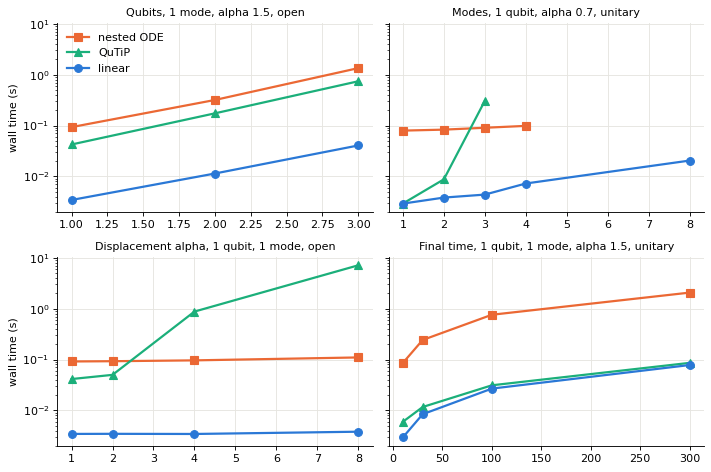

In [9]:
chosen = ['Qubits, 1 mode, alpha 1.5, open', 'Modes, 1 qubit, alpha 0.7, unitary', 'Displacement alpha, 1 qubit, 1 mode, open', 'Final time, 1 qubit, 1 mode, alpha 1.5, unitary']
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharey=True)
for ax, title in zip(axes.ravel(), chosen):
    values, times = curves[title]
    for i, style in ((1, ODE), (2, QUTIP), (0, LINEAR)):
        ax.semilogy(values, [cost[i] for cost in times], **style)
    ax.set_title(title, fontsize=10)
axes[0, 0].legend(frameon=False)
for ax in axes[:, 0]:
    ax.set_ylabel('wall time (s)')
plt.tight_layout()
plt.show()

## Summary

Measured in the run above, on one BLAS thread. Timings of a few ms were repeatable to about 10% across these sweeps; with default threading they were not.

**Accuracy.** The linear map reaches 1e-12 to 1e-15 against the reference on every grid, and matches QuTiP down to QuTiP's own tolerance. The nested ODEs are limited by their interpolation on `t_eval`, not by ODE integration: about 3e-4 on the QRDM with 21 output points, 1e-11 with 1601. The joint ODE, with no interpolation, gets 1.6e-12 at 21 points, so the fair accuracy gap to an ODE is small and the speed gap is what remains.

**Against ODEs.** At 21 output points the linear map takes 3.2 ms, against 78 ms for the joint ODE and 86 ms for the nested ODEs, so it is about 25 times faster, and in the size sweeps 7 to 35 times faster than the nested ODEs. Its cost grows with the number of output points and the ODE's does not, so **on dense grids the nested ODE is faster**: with one qubit and one mode the two cross near 1100 points, and at 1601 points the ODE takes 0.09 s against 0.13 s.

**Against QuTiP.** QuTiP times cover the QRDM only, while the linear map also returns every $\sigma_{jk}$ and $\bar r_{jk}$. There is no single winner.
- **Pure states with few modes: QuTiP is competitive or faster.** It is already ahead at 2 qubits (5.6 ms against 9.9 ms) and 6.6 times faster at 4 qubits (21 ms against 140 ms), because its cost grows with $2^N$ and the linear map's with the $2^{N-1}(2^N+1)$ branch pairs. To $\tau=300$ with one qubit the two are about equal (78 ms against 86 ms).
- **Open dynamics, several modes, or strong displacement and squeezing: the linear map is far ahead.** Open, 2 modes: 3.8 ms against 5.0 s. Open, $\alpha=8$: 3.8 ms against 7.1 s, cutoff 112. Pure, $s=1/64$: 3.1 ms against 0.98 s, cutoff 450. Pure, 3 modes: 4.4 ms against 0.31 s.

**Dependence on squeezing.** The cost does not follow the Fock cutoff, but it is not flat either: at 21 output points it rises from 3.0 ms at $s=1$ to 4.7 ms at $s=10^{-8}$ and 6.3 ms at $s=10^{-12}$, because the first steps have to resolve a fast collapse of $\sigma$. A path that keeps returning to large $\sigma$ pays this on each return. Displacement has no effect on the unitary cost (2.9 ms from $\alpha=1$ to 8).

The linear map only covers the case the paper's formalism covers, qubit-diagonal Hamiltonians with Gaussian dynamics. QuTiP needs neither restriction.